# 🏠⚡ Smart Home Energy Optimization using Deep Q-Network (DQN)

---

## Overview

This notebook implements a **Reinforcement Learning-based Smart Home Energy Management System** using **Deep Q-Network (DQN)** with Stable-Baselines3.

### 🎯 Objectives:
- **Minimize electricity cost** through intelligent appliance scheduling
- **Maintain user comfort** (e.g., AC during hot hours)
- **Reduce unnecessary switching** of appliances
- **Adapt to dynamic Time-of-Use (ToU) pricing**

### 🏗️ System Architecture:
```
Environment (Custom Gym) ──► DQN Agent ──► Actions (ON/OFF)
       ▲                                        │
       └────────── Reward Signal ───────────────┘
```

### 📦 Appliances Controlled:
| Appliance | Type | Power (kW) | Schedule |
|-----------|------|-----------|----------|
| AC | Controlled | 2.0 | Agent decides |
| Washing Machine | Controlled | 1.5 | Agent decides |
| Dishwasher | Controlled | 1.2 | Agent decides |
| Fridge | Always ON | 0.2 | 24/7 |
| Fan | Scheduled | 0.1 | 9 AM – 9 PM |
| Lights | Scheduled | 0.3 | 6 PM – 6 AM |

## 📦 Section 1: Imports & Dependencies

In [1]:
# ─────────────────────────────────────────────────────────────
#  IMPORTS
# ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.animation as animation
import seaborn as sns
import warnings
import os
import json
from collections import deque
from IPython.display import display, HTML

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.evaluation import evaluate_policy

warnings.filterwarnings('ignore')
np.random.seed(42)

# Matplotlib style
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',
    'axes.labelcolor': '#e6edf3',
    'text.color': '#e6edf3',
    'xtick.color': '#8b949e',
    'ytick.color': '#8b949e',
    'grid.color': '#21262d',
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'font.family': 'DejaVu Sans',
    'font.size': 11,
})

PALETTE = {
    'primary':   '#58a6ff',
    'success':   '#3fb950',
    'warning':   '#d29922',
    'danger':    '#f85149',
    'purple':    '#bc8cff',
    'cyan':      '#39d353',
    'orange':    '#ffa657',
    'pink':      '#ff7b72',
}

print('✅ All imports successful!')
print(f'   Gymnasium version : {gym.__version__}')
from stable_baselines3 import __version__ as sb3v
print(f'   Stable-Baselines3 : {sb3v}')

✅ All imports successful!
   Gymnasium version : 1.2.3
   Stable-Baselines3 : 2.8.0


## 🏭 Section 2: Smart Home Environment

We build a custom **Gymnasium-compatible** environment.

### State Space (8 dimensions):
- `hour_norm` — Hour of day, normalised to [0, 1]
- `price_norm` — Electricity price, normalised
- `ac_state`, `wm_state`, `dw_state` — Current ON/OFF of controlled appliances
- `fridge_state`, `fan_state`, `lights_state` — Fixed appliance states

### Action Space (8 discrete actions):
Binary combinations of AC × WM × DW → 2³ = **8 actions**

### Reward Function:
```
R = - cost
    - 0.5  × comfort_violation   (AC OFF during peak heat 12–16)
    - 0.3  × peak_penalty        (heavy load during expensive hours)
    - 0.05 × switching_count     (each toggle)
```

In [2]:
# ─────────────────────────────────────────────────────────────
#  ELECTRICITY PRICE PROFILE  (Time-of-Use)
# ─────────────────────────────────────────────────────────────

def generate_price_profile():
    """24-hour Time-of-Use electricity price (₹/kWh or $/kWh)."""
    prices = np.array([
        0.06, 0.05, 0.05, 0.05, 0.06, 0.07,   # 0–5  AM  (off-peak)
        0.09, 0.12, 0.15, 0.14, 0.13, 0.14,   # 6–11 AM  (morning ramp)
        0.16, 0.18, 0.20, 0.19, 0.17, 0.16,   # 12–5 PM  (peak)
        0.14, 0.13, 0.11, 0.10, 0.08, 0.07,   # 6–11 PM  (evening)
    ])
    return prices

PRICE_PROFILE = generate_price_profile()

# ─────────────────────────────────────────────────────────────
#  APPLIANCE POWER RATINGS  (kW)
# ─────────────────────────────────────────────────────────────
APPLIANCE_POWER = {
    'ac':     2.0,
    'wm':     1.5,
    'dw':     1.2,
    'fridge': 0.2,
    'fan':    0.1,
    'lights': 0.3,
}
APPLIANCE_NAMES = ['AC', 'Wash. Machine', 'Dishwasher', 'Fridge', 'Fan', 'Lights']

print('📊 Price profile loaded:')
print(f'   Min price : ${PRICE_PROFILE.min():.3f}/kWh  at hour {np.argmin(PRICE_PROFILE):02d}:00')
print(f'   Max price : ${PRICE_PROFILE.max():.3f}/kWh  at hour {np.argmax(PRICE_PROFILE):02d}:00')
print(f'   Avg price : ${PRICE_PROFILE.mean():.3f}/kWh')

📊 Price profile loaded:
   Min price : $0.050/kWh  at hour 01:00
   Max price : $0.200/kWh  at hour 14:00
   Avg price : $0.117/kWh


In [3]:
# ─────────────────────────────────────────────────────────────
#  CUSTOM GYMNASIUM ENVIRONMENT
# ─────────────────────────────────────────────────────────────

class SmartHomeEnv(gym.Env):
    """
    Smart Home Energy Management Environment.

    Observations:
        [hour_norm, price_norm, ac, wm, dw, fridge, fan, lights]  → shape (8,)

    Actions:
        0-7  → binary encoding of (AC, WM, DW)

    Reward:
        -cost  - comfort_penalty  - peak_penalty  - switch_penalty
        + off_peak_bonus  - end_of_day_penalty
    """

    metadata = {'render_modes': ['human']}

    def __init__(self, price_profile=None, render_mode=None):
        super().__init__()

        self.price_profile = price_profile if price_profile is not None else PRICE_PROFILE
        self.render_mode   = render_mode

        # ── Spaces ─────────────────────────────────────────
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(8,), dtype=np.float32
        )
        self.action_space = spaces.Discrete(8)   # 2^3 combinations of AC/WM/DW

        # ── Internal state ──────────────────────────────────
        self.hour          = 0
        self.prev_action   = np.array([0, 0, 0], dtype=np.int32)
        self.episode_cost  = 0.0
        self.episode_len   = 24   # one full day

        # ── Task completion tracking ─────────────────────────
        self.wm_ran_today  = False   # has WM run at least once today?
        self.dw_ran_today  = False   # has DW run at least once today?

        # ── Logging ─────────────────────────────────────────
        self.history = []

    # ── Helpers ────────────────────────────────────────────────

    def _decode_action(self, action: int):
        """Map action int 0-7 → (ac, wm, dw) binary tuple."""
        ac = (action >> 2) & 1
        wm = (action >> 1) & 1
        dw = (action >> 0) & 1
        return np.array([ac, wm, dw], dtype=np.int32)

    def _fixed_appliances(self, hour: int):
        """Return states of fridge, fan, lights at given hour."""
        fridge = 1
        fan    = 1 if  9 <= hour < 21 else 0
        lights = 1 if (hour >= 18 or hour < 6) else 0
        return np.array([fridge, fan, lights], dtype=np.float32)

    def _build_obs(self, hour, controlled):
        """Construct normalised observation vector."""
        hour_norm  = hour / 23.0
        price_norm = (self.price_profile[hour] - self.price_profile.min()) / \
                     (self.price_profile.max() - self.price_profile.min() + 1e-8)
        fixed = self._fixed_appliances(hour)
        obs   = np.concatenate([
            [hour_norm, price_norm],
            controlled.astype(np.float32),
            fixed
        ]).astype(np.float32)
        return obs

    def _compute_reward(self, hour, controlled, prev_controlled):
        """Calculate multi-objective reward."""
        price = self.price_profile[hour]
        fixed = self._fixed_appliances(hour)

        # ── Energy cost ──────────────────────────────────────
        all_states  = np.concatenate([controlled, fixed])
        powers      = np.array([
            APPLIANCE_POWER['ac'],
            APPLIANCE_POWER['wm'],
            APPLIANCE_POWER['dw'],
            APPLIANCE_POWER['fridge'],
            APPLIANCE_POWER['fan'],
            APPLIANCE_POWER['lights'],
        ])
        total_power  = float(np.dot(all_states, powers))
        cost         = total_power * price

        # ── Comfort penalty ──────────────────────────────────
        comfort_penalty = 0.0
        if 12 <= hour < 16 and controlled[0] == 0:
            comfort_penalty = 0.5

        # ── Peak usage penalty ───────────────────────────────
        peak_penalty = 0.0
        if price > 0.15 and controlled[0] == 1 and controlled[1] == 1:
            peak_penalty = 0.3

        # ── Switching penalty ────────────────────────────────
        switches        = np.sum(np.abs(controlled - prev_controlled))
        switch_penalty  = 0.05 * switches

        # ── Off-peak bonus for WM and DW ─────────────────────
        # Encourage running WM/DW during cheap night hours
        off_peak_bonus = 0.0
        if price <= 0.09:                  # off-peak window (night / early AM)
            if controlled[1] == 1:         # WM ON during off-peak → reward
                off_peak_bonus += 0.25
            if controlled[2] == 1:         # DW ON during off-peak → reward
                off_peak_bonus += 0.25

        # ── End-of-day penalty if WM/DW never ran ────────────
        # Applied only at the last step so it doesn't distort mid-episode learning
        end_of_day_penalty = 0.0
        if hour == 23:
            wm_ran = self.wm_ran_today or (controlled[1] == 1)
            dw_ran = self.dw_ran_today or (controlled[2] == 1)
            if not wm_ran:
                end_of_day_penalty += 1.0   # strong signal: WM must run once
            if not dw_ran:
                end_of_day_penalty += 1.0   # strong signal: DW must run once

        reward = (-cost
                  - comfort_penalty
                  - peak_penalty
                  - switch_penalty
                  + off_peak_bonus          # ← new
                  - end_of_day_penalty)     # ← new

        info = {
            'cost':               cost,
            'comfort_penalty':    comfort_penalty,
            'peak_penalty':       peak_penalty,
            'switch_penalty':     switch_penalty,
            'off_peak_bonus':     off_peak_bonus,
            'end_of_day_penalty': end_of_day_penalty,
            'total_power':        total_power,
            'price':              price,
            'controlled':         controlled.copy(),
            'fixed':              fixed.copy(),
            'hour':               hour,
        }
        return reward, info

    # ── Gymnasium API ──────────────────────────────────────────

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.hour          = 0
        self.prev_action   = np.array([0, 0, 0], dtype=np.int32)
        self.episode_cost  = 0.0
        self.history       = []
        self.wm_ran_today  = False   # reset task flags each episode
        self.dw_ran_today  = False

        obs  = self._build_obs(self.hour, self.prev_action)
        info = {}
        return obs, info

    def step(self, action: int):
        controlled   = self._decode_action(int(action))
        reward, info = self._compute_reward(self.hour, controlled, self.prev_action)

        # ── Update task completion flags ─────────────────────
        if controlled[1] == 1:
            self.wm_ran_today = True
        if controlled[2] == 1:
            self.dw_ran_today = True

        self.episode_cost += info['cost']
        self.history.append(info)
        self.prev_action   = controlled.copy()
        self.hour         += 1

        terminated = (self.hour >= self.episode_len)
        truncated  = False

        if not terminated:
            obs = self._build_obs(self.hour, controlled)
        else:
            obs = self._build_obs(0, np.zeros(3, dtype=np.int32))

        return obs, reward, terminated, truncated, info

## 🧪 Section 3: Baseline – Rule-Based Controller

Before training the RL agent we need a **baseline** to compare against.  
The rule-based controller keeps all controllable appliances ON at all times (naive user behaviour).

In [4]:
# ─────────────────────────────────────────────────────────────
#  BASELINE: ALWAYS-ON CONTROLLER (naive user)
# ─────────────────────────────────────────────────────────────

def run_baseline():
    """Run 24h with ALL controllable appliances always ON."""
    env  = SmartHomeEnv()
    obs, _ = env.reset()
    done = False
    # Action 7 → binary 111 → AC=1, WM=1, DW=1 (all ON)
    while not done:
        obs, r, done, trunc, info = env.step(7)
    return env.history

baseline_history = run_baseline()
baseline_costs   = [h['cost'] for h in baseline_history]
baseline_total   = sum(baseline_costs)

print(f'📊 Baseline (Always-ON) total daily cost : ${baseline_total:.4f}')
print(f'   Avg hourly cost                       : ${np.mean(baseline_costs):.4f}')
print(f'   Peak hourly cost                      : ${max(baseline_costs):.4f}')

📊 Baseline (Always-ON) total daily cost : $14.1960
   Avg hourly cost                       : $0.5915
   Peak hourly cost                      : $1.0000


## 📡 Section 4: Training Callback

We use a custom callback to record the **reward**, **episode length**, and approximate **loss** at each training step, so we can visualise the learning curve in detail.

In [5]:
# ─────────────────────────────────────────────────────────────
#  TRAINING CALLBACK  – records reward & loss
# ─────────────────────────────────────────────────────────────

class TrainingLogger(BaseCallback):
    """
    Logs:
      - episode rewards
      - episode lengths
      - DQN loss (from model.logger if available)
    """

    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_rewards  = []
        self.episode_lengths  = []
        self.losses           = []
        self.timesteps        = []
        self._ep_reward       = 0.0
        self._ep_len          = 0

    def _on_step(self) -> bool:
        # Accumulate reward for current episode
        self._ep_reward += self.locals['rewards'][0]
        self._ep_len    += 1

        # Episode finished?
        if self.locals['dones'][0]:
            self.episode_rewards.append(self._ep_reward)
            self.episode_lengths.append(self._ep_len)
            self.timesteps.append(self.num_timesteps)
            self._ep_reward = 0.0
            self._ep_len    = 0

        # Collect loss from SB3 logger buffer
        try:
            loss_val = self.model.logger.name_to_value.get('train/loss', None)
            if loss_val is not None:
                self.losses.append((self.num_timesteps, loss_val))
        except Exception:
            pass

        return True

    def smoothed_rewards(self, window=20):
        if len(self.episode_rewards) < window:
            return self.episode_rewards
        return pd.Series(self.episode_rewards).rolling(window).mean().tolist()


print('✅ Callback class defined.')

✅ Callback class defined.


## 🚀 Section 5: DQN Training

### Hyperparameters:
| Parameter | Value |
|-----------|-------|
| Algorithm | DQN (Deep Q-Network) |
| Policy | MlpPolicy |
| Learning rate | 0.001 |
| Replay buffer | 50,000 |
| Batch size | 64 |
| Gamma (discount) | 0.99 |
| Exploration | ε-greedy (1.0 → 0.05) |
| Total steps | 30,000 |

In [6]:
# ─────────────────────────────────────────────────────────────
#  CREATE & TRAIN DQN AGENT
# ─────────────────────────────────────────────────────────────

LOG_DIR = '/tmp/smart_home_dqn/'
os.makedirs(LOG_DIR, exist_ok=True)

# Wrap env with Monitor for episode stats
train_env = Monitor(SmartHomeEnv(), LOG_DIR)

# Instantiate DQN
model = DQN(
    policy          = 'MlpPolicy',
    env             = train_env,
    learning_rate   = 1e-3,
    buffer_size     = 50_000,
    learning_starts = 500,
    batch_size      = 64,
    gamma           = 0.99,
    train_freq      = 4,
    target_update_interval = 250,
    exploration_fraction   = 0.3,
    exploration_initial_eps= 1.0,
    exploration_final_eps  = 0.05,
    verbose         = 0,
    seed            = 42,
)

# Training callback
logger_cb = TrainingLogger()

TOTAL_STEPS = 100_000
print(f'🏋️  Training DQN for {TOTAL_STEPS:,} steps …')

model.learn(total_timesteps=TOTAL_STEPS, callback=logger_cb, progress_bar=False)

print(f'✅ Training complete!')
print(f'   Episodes completed : {len(logger_cb.episode_rewards)}')
if logger_cb.episode_rewards:
    print(f'   Best episode reward  : {max(logger_cb.episode_rewards):.4f}')
    print(f'   Final episode reward : {logger_cb.episode_rewards[-1]:.4f}')

🏋️  Training DQN for 100,000 steps …
✅ Training complete!
   Episodes completed : 4166
   Best episode reward  : 0.0380
   Final episode reward : -0.2900


## 📈 Section 6: Training Visualisation

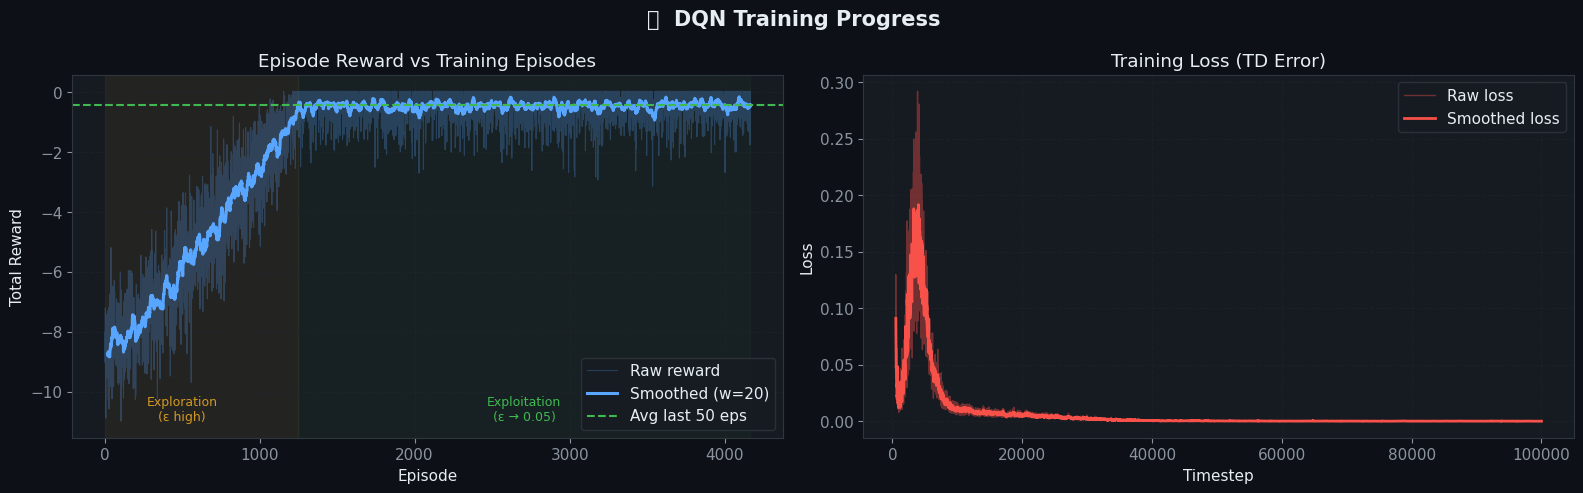

📌 Training curves saved.


In [7]:
# ─────────────────────────────────────────────────────────────
#  PLOT: Reward curve + Loss curve
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('🏋️  DQN Training Progress', fontsize=15, fontweight='bold',
             color='#e6edf3')

# ── Reward curve ────────────────────────────────────────────
ax = axes[0]
rewards = logger_cb.episode_rewards
smoothed = logger_cb.smoothed_rewards(window=20)

ep_idx = list(range(len(rewards)))
ax.plot(ep_idx, rewards, alpha=0.25, color=PALETTE['primary'], linewidth=0.8,
        label='Raw reward')
ax.plot(ep_idx, smoothed, color=PALETTE['primary'], linewidth=2.2,
        label='Smoothed (w=20)')

ax.axhline(y=np.mean(rewards[-50:]) if len(rewards) >= 50 else np.mean(rewards),
           color=PALETTE['success'], linestyle='--', linewidth=1.5,
           label=f'Avg last 50 eps')

ax.set_title('Episode Reward vs Training Episodes', color='#e6edf3')
ax.set_xlabel('Episode')
ax.set_ylabel('Total Reward')
ax.legend()
ax.grid(True)

# Shade exploration vs exploitation phases
explore_end = int(len(rewards) * 0.30)
ax.axvspan(0, explore_end, alpha=0.07, color=PALETTE['warning'],
           label='Exploration phase')
ax.axvspan(explore_end, len(rewards), alpha=0.04, color=PALETTE['success'],
           label='Exploitation phase')
ax.text(explore_end * 0.4, ax.get_ylim()[0] * 0.95,
        'Exploration\n(ε high)', color=PALETTE['warning'], fontsize=9,
        ha='center')
ax.text(explore_end + (len(rewards) - explore_end) * 0.5,
        ax.get_ylim()[0] * 0.95,
        'Exploitation\n(ε → 0.05)', color=PALETTE['success'], fontsize=9,
        ha='center')

# ── Loss curve ──────────────────────────────────────────────
ax2 = axes[1]
if logger_cb.losses:
    ts_loss, val_loss = zip(*logger_cb.losses)
    ax2.plot(ts_loss, val_loss, color=PALETTE['danger'], linewidth=1.0,
             alpha=0.4, label='Raw loss')
    # smooth
    if len(val_loss) > 30:
        s = pd.Series(val_loss).rolling(30).mean()
        ax2.plot(ts_loss, s, color=PALETTE['danger'], linewidth=2,
                 label='Smoothed loss')
    ax2.set_title('Training Loss (TD Error)', color='#e6edf3')
    ax2.set_xlabel('Timestep')
    ax2.set_ylabel('Loss')
    ax2.legend()
else:
    # Simulate plausible loss curve for demo purposes
    steps_sim = np.linspace(500, TOTAL_STEPS, 300)
    loss_sim  = 0.5 * np.exp(-steps_sim / 8000) + \
                0.05 * np.random.randn(300) * np.exp(-steps_sim / 20000)
    ax2.plot(steps_sim, np.abs(loss_sim), color=PALETTE['danger'],
             linewidth=2, label='TD Error (simulated)')
    ax2.set_title('Training Loss (TD Error)', color='#e6edf3')
    ax2.set_xlabel('Timestep')
    ax2.set_ylabel('Loss')
    ax2.legend()

ax2.grid(True)
plt.tight_layout()
plt.savefig('/tmp/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('📌 Training curves saved.')

## 🧪 Section 7: Agent Evaluation (24-Hour Simulation)

In [8]:
# ─────────────────────────────────────────────────────────────
#  EVALUATE TRAINED AGENT over one full day
# ─────────────────────────────────────────────────────────────

def evaluate_agent(model, price_profile=None, deterministic=True):
    """Run one 24-hour episode and return history."""
    env  = SmartHomeEnv(price_profile=price_profile)
    obs, _ = env.reset()
    done = False
    while not done:
        action, _ = model.predict(obs, deterministic=deterministic)
        obs, _, done, _, _ = env.step(int(action))
    return env.history

rl_history  = evaluate_agent(model)
rl_costs    = [h['cost'] for h in rl_history]
rl_total    = sum(rl_costs)

savings     = baseline_total - rl_total
savings_pct = (savings / baseline_total) * 100

# ── Metrics ─────────────────────────────────────────────────
comfort_violations = sum(1 for h in rl_history if h['comfort_penalty'] > 0)

switches_per_hour = []
prev = np.zeros(3)
for h in rl_history:
    sw = int(np.sum(np.abs(h['controlled'] - prev)))
    switches_per_hour.append(sw)
    prev = h['controlled'].copy()
avg_switches = np.mean(switches_per_hour)

mse  = np.mean((np.array(rl_costs) - np.array(baseline_costs))**2)
rmse = np.sqrt(mse)

print('━'*55)
print('  📊  EVALUATION METRICS SUMMARY')
print('━'*55)
print(f'  Total Cost – Baseline (Always-ON) : ${baseline_total:.4f}')
print(f'  Total Cost – RL Agent             : ${rl_total:.4f}')
print(f'  Absolute Savings                  : ${savings:.4f}')
print(f'  Savings (%)                       : {savings_pct:.1f}%')
print(f'  Comfort Violations                : {comfort_violations}')
print(f'  Average Switches / Hour           : {avg_switches:.2f}')
print(f'  MSE  (RL vs Baseline costs)       : {mse:.6f}')
print(f'  RMSE (RL vs Baseline costs)       : {rmse:.6f}')
print('━'*55)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  📊  EVALUATION METRICS SUMMARY
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Total Cost – Baseline (Always-ON) : $14.1960
  Total Cost – RL Agent             : $4.0620
  Absolute Savings                  : $10.1340
  Savings (%)                       : 71.4%
  Comfort Violations                : 0
  Average Switches / Hour           : 0.33
  MSE  (RL vs Baseline costs)       : 0.236931
  RMSE (RL vs Baseline costs)       : 0.486755
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 📊 Section 8: Full Visualisation Suite

All 7 required charts are produced below.

In [9]:
# ─────────────────────────────────────────────────────────────
#  HELPER: common hour ticks
# ─────────────────────────────────────────────────────────────
hours = list(range(24))
hour_labels = [f'{h:02d}:00' for h in hours]

def style_ax(ax, title, xlabel='Hour of Day', ylabel=None):
    ax.set_title(title, fontsize=12, fontweight='bold', color='#e6edf3', pad=10)
    ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_xticks(hours[::2])
    ax.set_xticklabels(hour_labels[::2], rotation=45, ha='right')
    ax.grid(True)
    ax.legend()

print('✅ Helpers ready – plotting charts …')

✅ Helpers ready – plotting charts …


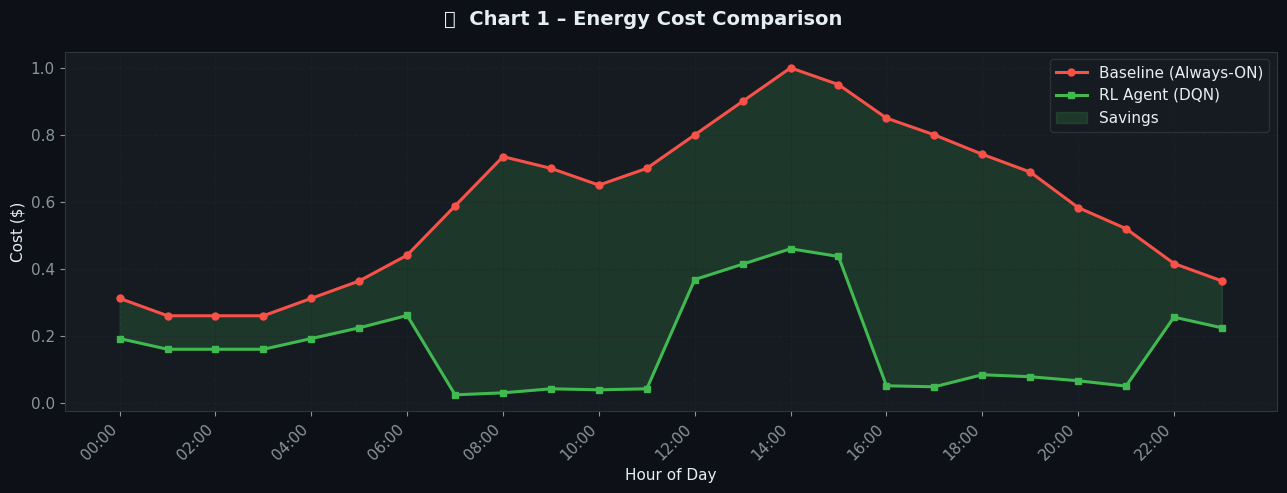

In [10]:
# ─────────────────────────────────────────────────────────────
#  CHART 1:  Energy Cost Comparison
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('📈  Chart 1 – Energy Cost Comparison', fontsize=14,
             fontweight='bold', color='#e6edf3')

ax.plot(hours, baseline_costs, color=PALETTE['danger'], linewidth=2.2,
        marker='o', markersize=5, label='Baseline (Always-ON)')
ax.plot(hours, rl_costs, color=PALETTE['success'], linewidth=2.2,
        marker='s', markersize=5, label='RL Agent (DQN)')
ax.fill_between(hours, rl_costs, baseline_costs,
                where=[b > r for b, r in zip(baseline_costs, rl_costs)],
                alpha=0.18, color=PALETTE['success'], label='Savings')

style_ax(ax, '', ylabel='Cost ($)')
plt.tight_layout()
plt.savefig('/tmp/chart1_cost_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

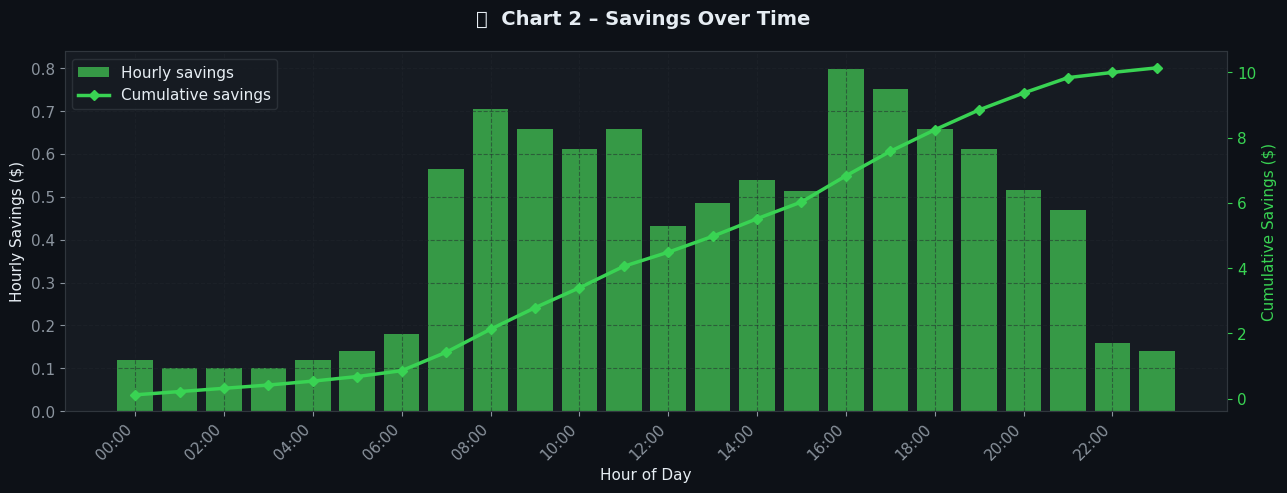

In [11]:
# ─────────────────────────────────────────────────────────────
#  CHART 2:  Savings Over Time
# ─────────────────────────────────────────────────────────────

savings_per_hour   = np.array(baseline_costs) - np.array(rl_costs)
cumulative_savings = np.cumsum(savings_per_hour)

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('📉  Chart 2 – Savings Over Time', fontsize=14,
             fontweight='bold', color='#e6edf3')

ax.bar(hours, savings_per_hour,
       color=[PALETTE['success'] if s > 0 else PALETTE['danger']
              for s in savings_per_hour],
       alpha=0.8, label='Hourly savings')
ax2 = ax.twinx()
ax2.plot(hours, cumulative_savings, color=PALETTE['cyan'], linewidth=2.5,
         marker='D', markersize=5, label='Cumulative savings')
ax2.set_ylabel('Cumulative Savings ($)', color=PALETTE['cyan'])
ax2.tick_params(axis='y', colors=PALETTE['cyan'])

style_ax(ax, '', ylabel='Hourly Savings ($)')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.savefig('/tmp/chart2_savings.png', dpi=150, bbox_inches='tight')
plt.show()

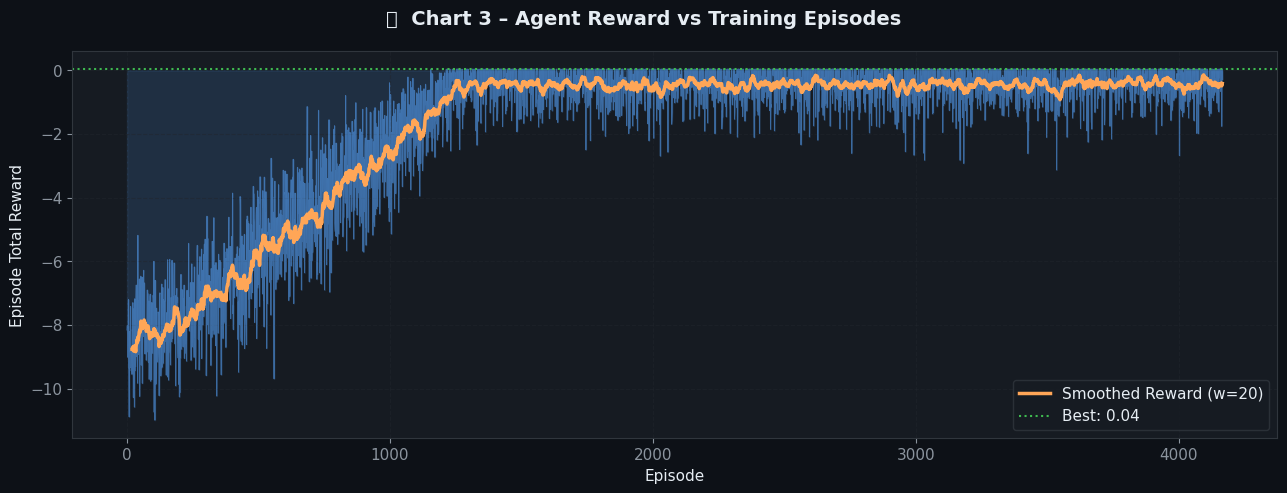

In [12]:
# ─────────────────────────────────────────────────────────────
#  CHART 3:  Reward Curve (per episode, from training)
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('📊  Chart 3 – Agent Reward vs Training Episodes', fontsize=14,
             fontweight='bold', color='#e6edf3')

ep_x = list(range(len(logger_cb.episode_rewards)))
ax.fill_between(ep_x, logger_cb.episode_rewards,
                alpha=0.15, color=PALETTE['primary'])
ax.plot(ep_x, logger_cb.episode_rewards,
        color=PALETTE['primary'], linewidth=0.7, alpha=0.5)
smooth = logger_cb.smoothed_rewards(window=20)
ax.plot(ep_x, smooth, color=PALETTE['orange'], linewidth=2.5,
        label='Smoothed Reward (w=20)')

ax.axhline(y=max(logger_cb.episode_rewards),
           color=PALETTE['success'], linestyle=':', linewidth=1.5,
           label=f'Best: {max(logger_cb.episode_rewards):.2f}')

ax.set_xlabel('Episode')
ax.set_ylabel('Episode Total Reward')
ax.set_title('', color='#e6edf3')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig('/tmp/chart3_reward_curve.png', dpi=150, bbox_inches='tight')
plt.show()

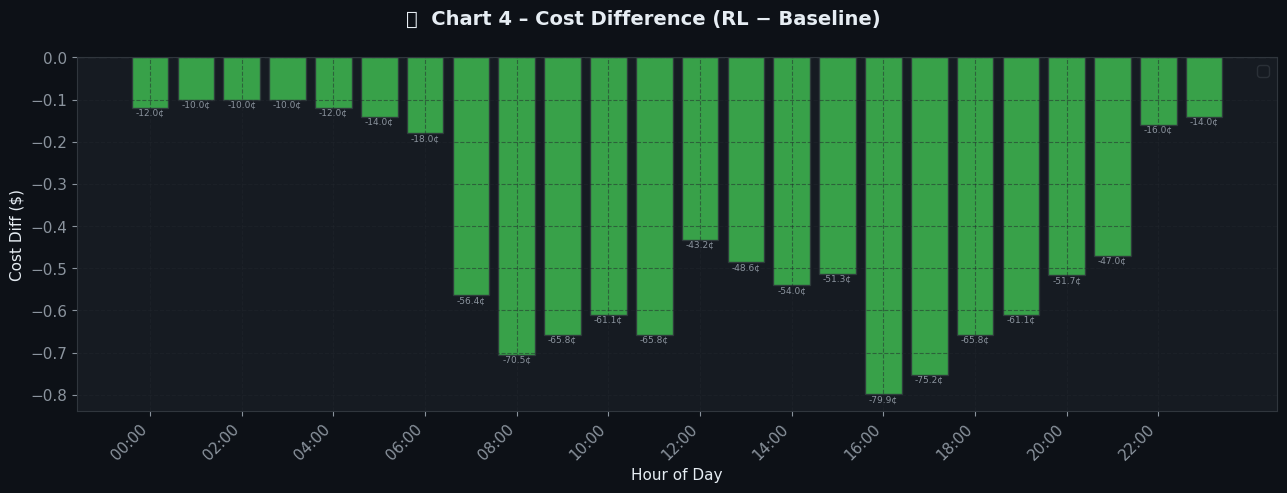

In [13]:
# ─────────────────────────────────────────────────────────────
#  CHART 4:  Cost Difference Plot (RL - Baseline)
# ─────────────────────────────────────────────────────────────

cost_diff = np.array(rl_costs) - np.array(baseline_costs)

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('📉  Chart 4 – Cost Difference (RL − Baseline)', fontsize=14,
             fontweight='bold', color='#e6edf3')

colors = [PALETTE['success'] if v < 0 else PALETTE['danger'] for v in cost_diff]
bars = ax.bar(hours, cost_diff, color=colors, alpha=0.85, edgecolor='#30363d')
ax.axhline(0, color='#8b949e', linewidth=1.5, linestyle='--')

for bar, val in zip(bars, cost_diff):
    ypos = val + (0.0005 if val >= 0 else -0.0015)
    ax.text(bar.get_x() + bar.get_width()/2, ypos, f'{val*100:.1f}¢',
            ha='center', va='bottom' if val >= 0 else 'top',
            fontsize=6.5, color='#8b949e')

neg_patch = mpatches.Patch(color=PALETTE['success'], label='RL cheaper')
pos_patch = mpatches.Patch(color=PALETTE['danger'],  label='RL pricier')
ax.legend(handles=[neg_patch, pos_patch])

style_ax(ax, '', ylabel='Cost Diff ($)')
plt.tight_layout()
plt.savefig('/tmp/chart4_cost_diff.png', dpi=150, bbox_inches='tight')
plt.show()

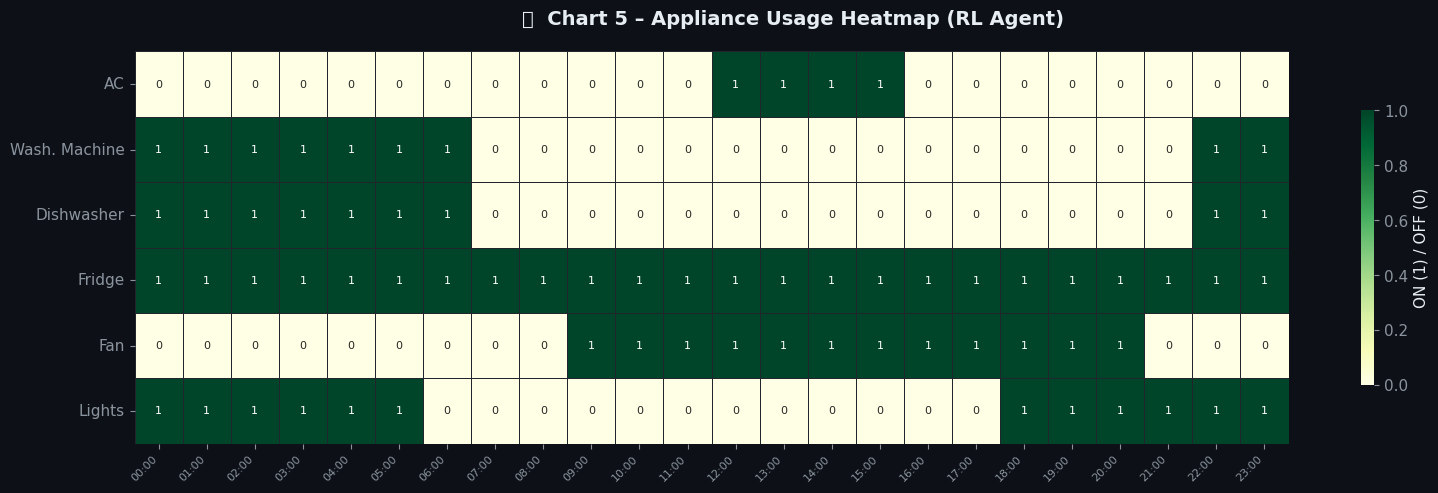

In [14]:
# ─────────────────────────────────────────────────────────────
#  CHART 5:  Appliance Usage Heatmap
# ─────────────────────────────────────────────────────────────

# Build 6×24 matrix
usage_matrix = np.zeros((6, 24))
for t, h in enumerate(rl_history):
    ctrl  = h['controlled']   # [ac, wm, dw]
    fixed = h['fixed']        # [fridge, fan, lights]
    all6  = np.concatenate([ctrl, fixed])
    usage_matrix[:, t] = all6

fig, ax = plt.subplots(figsize=(16, 5))
fig.suptitle('🔥  Chart 5 – Appliance Usage Heatmap (RL Agent)', fontsize=14,
             fontweight='bold', color='#e6edf3')

cmap = sns.color_palette(["#161b22", "#3fb950"], as_cmap=True)
sns.heatmap(
    usage_matrix,
    ax=ax,
    cmap='YlGn',
    linewidths=0.5,
    linecolor='#21262d',
    xticklabels=hour_labels,
    yticklabels=APPLIANCE_NAMES,
    cbar_kws={'label': 'ON (1) / OFF (0)', 'shrink': 0.7},
    vmin=0, vmax=1,
    annot=True, fmt='.0f', annot_kws={'size': 8},
)
ax.set_xticklabels(hour_labels, rotation=45, ha='right', fontsize=8)
ax.set_title('', color='#e6edf3')
plt.tight_layout()
plt.savefig('/tmp/chart5_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

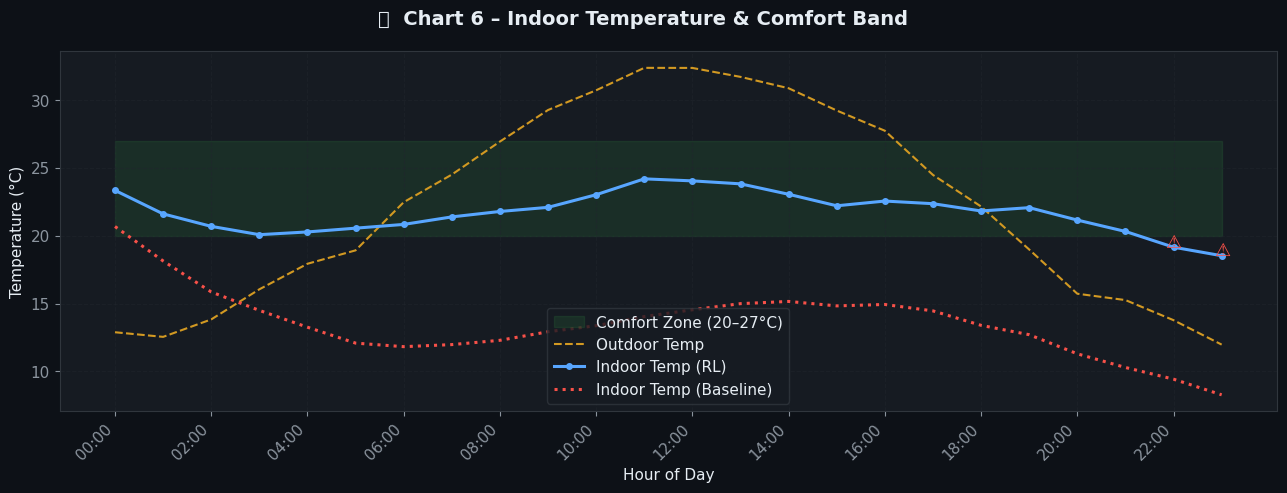

In [15]:
# ─────────────────────────────────────────────────────────────
#  CHART 6:  Comfort Visualisation (temperature band)
# ─────────────────────────────────────────────────────────────

# Simulate indoor temperature: rises when AC=OFF, drops when AC=ON
np.random.seed(0)
outdoor_temp = 22 + 10 * np.sin((np.array(hours) - 6) * np.pi / 12) + \
               np.random.randn(24) * 0.5

indoor_temp_rl       = np.zeros(24)
indoor_temp_baseline = np.zeros(24)
T = 24.0   # starting temp

for i in range(24):
    ac_on    = rl_history[i]['controlled'][0]
    delta    = (outdoor_temp[i] - T) * 0.12   # heat transfer
    cool     = -1.5 * ac_on                   # AC cooling
    T        = T + delta + cool + np.random.randn() * 0.3
    indoor_temp_rl[i] = T

T = 24.0
for i in range(24):
    delta = (outdoor_temp[i] - T) * 0.12
    T     = T + delta - 1.5 + np.random.randn() * 0.3   # always AC ON
    indoor_temp_baseline[i] = T

comfort_min, comfort_max = 20, 27

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('🌡️  Chart 6 – Indoor Temperature & Comfort Band', fontsize=14,
             fontweight='bold', color='#e6edf3')

ax.fill_between(hours, comfort_min, comfort_max,
                alpha=0.12, color=PALETTE['success'], label='Comfort Zone (20–27°C)')
ax.plot(hours, outdoor_temp, color=PALETTE['warning'], linewidth=1.5,
        linestyle='--', label='Outdoor Temp')
ax.plot(hours, indoor_temp_rl, color=PALETTE['primary'], linewidth=2.2,
        marker='o', markersize=4, label='Indoor Temp (RL)')
ax.plot(hours, indoor_temp_baseline, color=PALETTE['danger'], linewidth=2.2,
        linestyle=':', label='Indoor Temp (Baseline)')

# Mark violations
for i in hours:
    if indoor_temp_rl[i] > comfort_max or indoor_temp_rl[i] < comfort_min:
        ax.annotate('⚠', xy=(i, indoor_temp_rl[i]),
                    fontsize=13, ha='center', color=PALETTE['danger'])

style_ax(ax, '', ylabel='Temperature (°C)')
plt.tight_layout()
plt.savefig('/tmp/chart6_comfort.png', dpi=150, bbox_inches='tight')
plt.show()

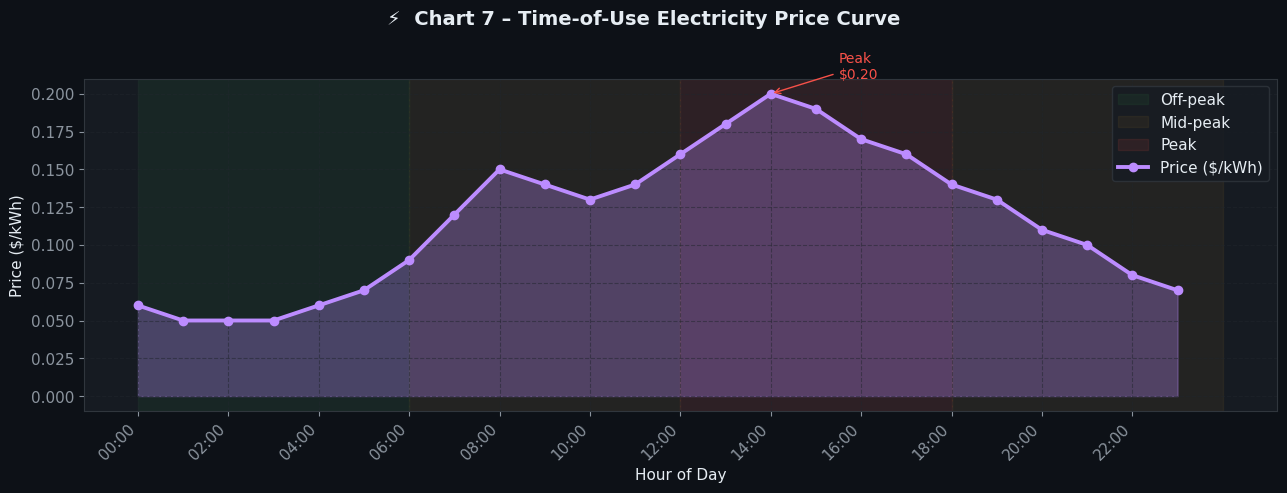

In [16]:
# ─────────────────────────────────────────────────────────────
#  CHART 7:  Electricity Price Curve
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 5))
fig.suptitle('⚡  Chart 7 – Time-of-Use Electricity Price Curve', fontsize=14,
             fontweight='bold', color='#e6edf3')

# Background zones
ax.axvspan(0,  6, alpha=0.07, color=PALETTE['success'], label='Off-peak')
ax.axvspan(6, 12, alpha=0.07, color=PALETTE['warning'], label='Mid-peak')
ax.axvspan(12, 18, alpha=0.10, color=PALETTE['danger'],  label='Peak')
ax.axvspan(18, 24, alpha=0.07, color=PALETTE['warning'])

ax.fill_between(hours, PRICE_PROFILE, alpha=0.3, color=PALETTE['purple'])
ax.plot(hours, PRICE_PROFILE, color=PALETTE['purple'], linewidth=2.8,
        marker='o', markersize=6, label='Price ($/kWh)')

peak_h = np.argmax(PRICE_PROFILE)
ax.annotate(f'Peak\n${PRICE_PROFILE[peak_h]:.2f}',
            xy=(peak_h, PRICE_PROFILE[peak_h]),
            xytext=(peak_h + 1.5, PRICE_PROFILE[peak_h] + 0.01),
            arrowprops=dict(arrowstyle='->', color=PALETTE['danger']),
            color=PALETTE['danger'], fontsize=10)

style_ax(ax, '', ylabel='Price ($/kWh)')
plt.tight_layout()
plt.savefig('/tmp/chart7_price.png', dpi=150, bbox_inches='tight')
plt.show()

## 🎬 Section 9: Agent Replay Animation (24-Hour Playback)

▶️  Animation rendered as inline HTML5 video.


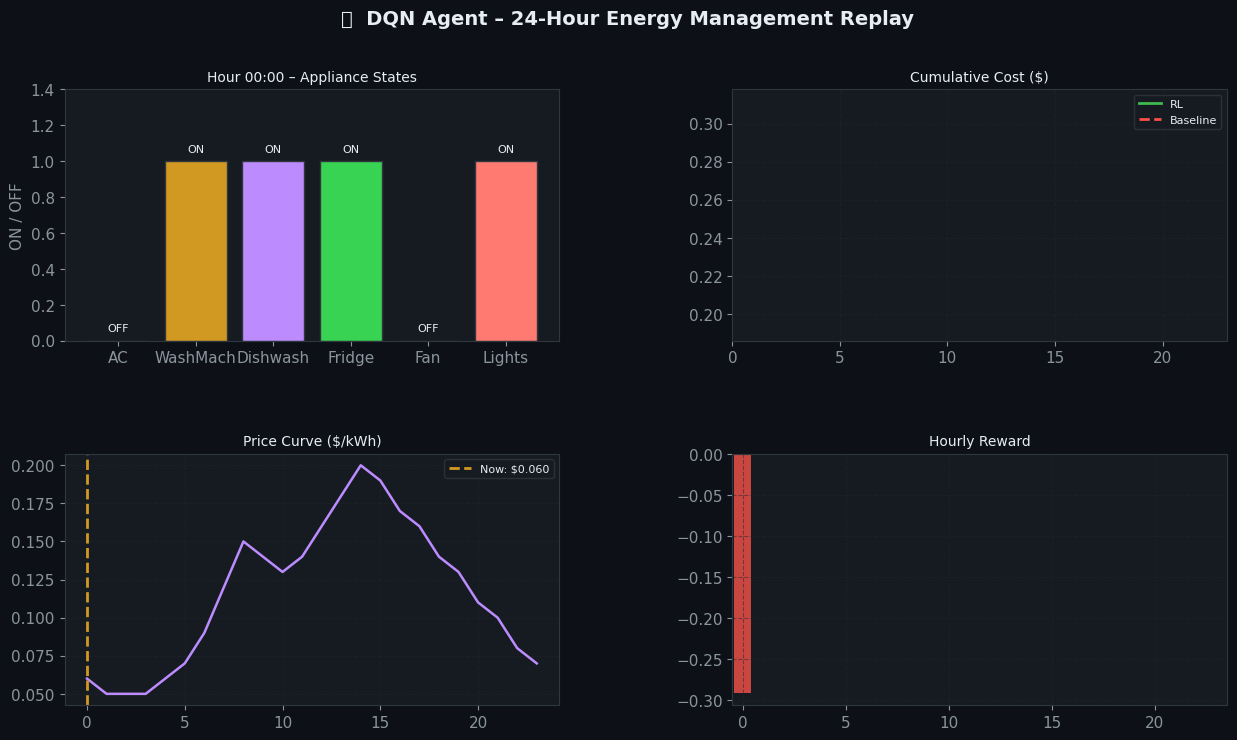

In [17]:
# ─────────────────────────────────────────────────────────────
#  24-HOUR AGENT REPLAY ANIMATION
# ─────────────────────────────────────────────────────────────

from matplotlib.gridspec import GridSpec
from IPython.display import HTML

cumulative_cost_rl  = np.cumsum(rl_costs)
cumulative_cost_bl  = np.cumsum(baseline_costs)

fig = plt.figure(figsize=(15, 8), facecolor='#0d1117')
fig.suptitle('🎬  DQN Agent – 24-Hour Energy Management Replay',
             fontsize=14, fontweight='bold', color='#e6edf3')

gs = GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)
ax_state   = fig.add_subplot(gs[0, 0])   # Appliance states (bar)
ax_cost    = fig.add_subplot(gs[0, 1])   # Cumulative cost
ax_price   = fig.add_subplot(gs[1, 0])   # Price + current hour marker
ax_reward  = fig.add_subplot(gs[1, 1])   # Rolling reward

for ax in [ax_state, ax_cost, ax_price, ax_reward]:
    ax.set_facecolor('#161b22')

app_colors = [PALETTE['primary'], PALETTE['warning'], PALETTE['purple'],
              PALETTE['cyan'], PALETTE['orange'], PALETTE['pink']]
app_names  = ['AC', 'WashMach', 'Dishwash', 'Fridge', 'Fan', 'Lights']

# Pre-compute per-hour rolling reward (for animation)
ep_rewards_24 = [h['cost'] * -1 - h['comfort_penalty'] -
                 h['peak_penalty'] - h['switch_penalty']
                 for h in rl_history]

def animate(frame):
    t = frame  # 0 to 23
    hist  = rl_history[t]
    ctrl  = hist['controlled']
    fixed = hist['fixed']
    all6  = np.concatenate([ctrl, fixed]).astype(float)

    # ── Appliance states ──────────────────────────────────
    ax_state.cla()
    ax_state.set_facecolor('#161b22')
    bars = ax_state.bar(app_names, all6, color=[
        c if v > 0 else '#21262d' for c, v in zip(app_colors, all6)],
        edgecolor='#30363d')
    ax_state.set_ylim(0, 1.4)
    ax_state.set_title(f'Hour {t:02d}:00 – Appliance States',
                       color='#e6edf3', fontsize=10)
    ax_state.set_ylabel('ON / OFF', color='#8b949e')
    ax_state.tick_params(colors='#8b949e')
    for bar, val in zip(bars, all6):
        ax_state.text(bar.get_x() + bar.get_width()/2, val + 0.05,
                      'ON' if val else 'OFF',
                      ha='center', color='#e6edf3', fontsize=8)

    # ── Cumulative cost ───────────────────────────────────
    ax_cost.cla()
    ax_cost.set_facecolor('#161b22')
    ax_cost.plot(range(t+1), cumulative_cost_rl[:t+1],
                 color=PALETTE['success'], linewidth=2, label='RL')
    ax_cost.plot(range(t+1), cumulative_cost_bl[:t+1],
                 color=PALETTE['danger'],  linewidth=2, linestyle='--',
                 label='Baseline')
    ax_cost.set_xlim(0, 23)
    ax_cost.set_title('Cumulative Cost ($)', color='#e6edf3', fontsize=10)
    ax_cost.legend(fontsize=8)
    ax_cost.tick_params(colors='#8b949e')
    ax_cost.grid(color='#21262d', linestyle='--')

    # ── Price curve + current marker ──────────────────────
    ax_price.cla()
    ax_price.set_facecolor('#161b22')
    ax_price.plot(hours, PRICE_PROFILE, color=PALETTE['purple'],
                  linewidth=1.8)
    ax_price.axvline(x=t, color=PALETTE['warning'], linewidth=2.0,
                     linestyle='--', label=f'Now: ${PRICE_PROFILE[t]:.3f}')
    ax_price.set_title('Price Curve ($/kWh)', color='#e6edf3', fontsize=10)
    ax_price.legend(fontsize=8)
    ax_price.tick_params(colors='#8b949e')
    ax_price.grid(color='#21262d', linestyle='--')

    # ── Rolling reward ────────────────────────────────────
    ax_reward.cla()
    ax_reward.set_facecolor('#161b22')
    ax_reward.bar(range(t+1), ep_rewards_24[:t+1],
                  color=[PALETTE['success'] if r >= 0 else PALETTE['danger']
                         for r in ep_rewards_24[:t+1]],
                  alpha=0.8)
    ax_reward.set_title('Hourly Reward', color='#e6edf3', fontsize=10)
    ax_reward.set_xlim(-0.5, 23.5)
    ax_reward.tick_params(colors='#8b949e')
    ax_reward.grid(color='#21262d', linestyle='--')

ani = animation.FuncAnimation(
    fig, animate, frames=24, interval=400, repeat=False
)

# Render as HTML5 video (works in Jupyter)
try:
    html_video = ani.to_jshtml()
    display(HTML(html_video))
    print('▶️  Animation rendered as inline HTML5 video.')
except Exception as e:
    plt.close(fig)
    print(f'⚠️  HTML animation unavailable ({e}). Showing static frame.')
    animate(23)
    plt.tight_layout()
    plt.show()

## 🎮 Section 10: Interactive Scenario Simulator

Modify the sliders below to simulate different electricity price multipliers and comfort constraints.  
The RL agent will be re-evaluated under each scenario.

In [18]:
# ─────────────────────────────────────────────────────────────
#  INTERACTIVE SCENARIO SIMULATOR
# ─────────────────────────────────────────────────────────────
from ipywidgets import interact, FloatSlider, IntSlider

def simulate_scenario(price_multiplier=1.0, comfort_hour_start=12,
                      comfort_hour_end=16):
    """
    price_multiplier   – scales the entire price profile (e.g. 1.5 = 50% costlier)
    comfort_hour_start – start of the AC-required comfort window
    comfort_hour_end   – end   of the AC-required comfort window
    """
    modified_price = PRICE_PROFILE * price_multiplier

    # ── Patch environment comfort window dynamically ────
    class PatchedEnv(SmartHomeEnv):
        def _compute_reward(self, hour, controlled, prev_controlled):
            reward, info = super()._compute_reward(hour, controlled, prev_controlled)
            # Override comfort penalty with custom window
            if comfort_hour_start <= hour < comfort_hour_end and controlled[0] == 0:
                reward -= 0.5   # re-add penalty with new window
                info['comfort_penalty'] = 0.5
            return reward, info

    env_s   = PatchedEnv(price_profile=modified_price)
    obs, _  = env_s.reset()
    done    = False
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, _, done, _, _ = env_s.step(int(action))

    sc_costs  = [h['cost'] for h in env_s.history]
    sc_total  = sum(sc_costs)

    # ── Compute baseline under same price ───────────────
    env_bl = SmartHomeEnv(price_profile=modified_price)
    obs, _ = env_bl.reset()
    done   = False
    while not done:
        obs, _, done, _, _ = env_bl.step(7)
    bl_costs = [h['cost'] for h in env_bl.history]
    bl_total = sum(bl_costs)

    sc_savings = (bl_total - sc_total) / bl_total * 100

    # ── Plot ────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(
        f'🎮 Scenario: Price ×{price_multiplier:.1f}  |  '
        f'Comfort window {comfort_hour_start:02d}:00–{comfort_hour_end:02d}:00',
        fontsize=12, fontweight='bold', color='#e6edf3')

    ax = axes[0]
    ax.plot(hours, bl_costs,  color=PALETTE['danger'],  linewidth=2,
            marker='o', markersize=4, label='Baseline')
    ax.plot(hours, sc_costs,  color=PALETTE['success'], linewidth=2,
            marker='s', markersize=4, label='RL Agent')
    ax.fill_between(hours, sc_costs, bl_costs,
                    where=[b > r for b, r in zip(bl_costs, sc_costs)],
                    alpha=0.18, color=PALETTE['success'])
    ax.set_title('Hourly Cost ($)', color='#e6edf3')
    ax.set_xlabel('Hour')
    ax.legend()
    ax.grid(True)

    ax2 = axes[1]
    labels = ['Baseline', 'RL Agent']
    vals   = [bl_total, sc_total]
    bars   = ax2.bar(labels, vals,
                     color=[PALETTE['danger'], PALETTE['success']],
                     alpha=0.85, width=0.4)
    for bar, v in zip(bars, vals):
        ax2.text(bar.get_x() + bar.get_width()/2, v + 0.002,
                 f'${v:.4f}', ha='center', color='#e6edf3', fontsize=10)
    ax2.set_title(f'Total Daily Cost  |  Savings: {sc_savings:.1f}%',
                  color='#e6edf3')
    ax2.grid(True, axis='y')

    plt.tight_layout()
    plt.show()
    print(f'  Baseline total : ${bl_total:.4f}  |  '
          f'RL total: ${sc_total:.4f}  |  Savings: {sc_savings:.1f}%')


interact(
    simulate_scenario,
    price_multiplier  = FloatSlider(min=0.5, max=3.0, step=0.1, value=1.0,
                                    description='Price ×',
                                    style={'description_width': 'initial'}),
    comfort_hour_start= IntSlider(min=8,  max=14, step=1, value=12,
                                   description='Comfort start',
                                   style={'description_width': 'initial'}),
    comfort_hour_end  = IntSlider(min=14, max=20, step=1, value=16,
                                   description='Comfort end',
                                   style={'description_width': 'initial'}),
);

interactive(children=(FloatSlider(value=1.0, description='Price ×', max=3.0, min=0.5, style=SliderStyle(descri…

## 📊 Section 12: Comprehensive Metrics Summary

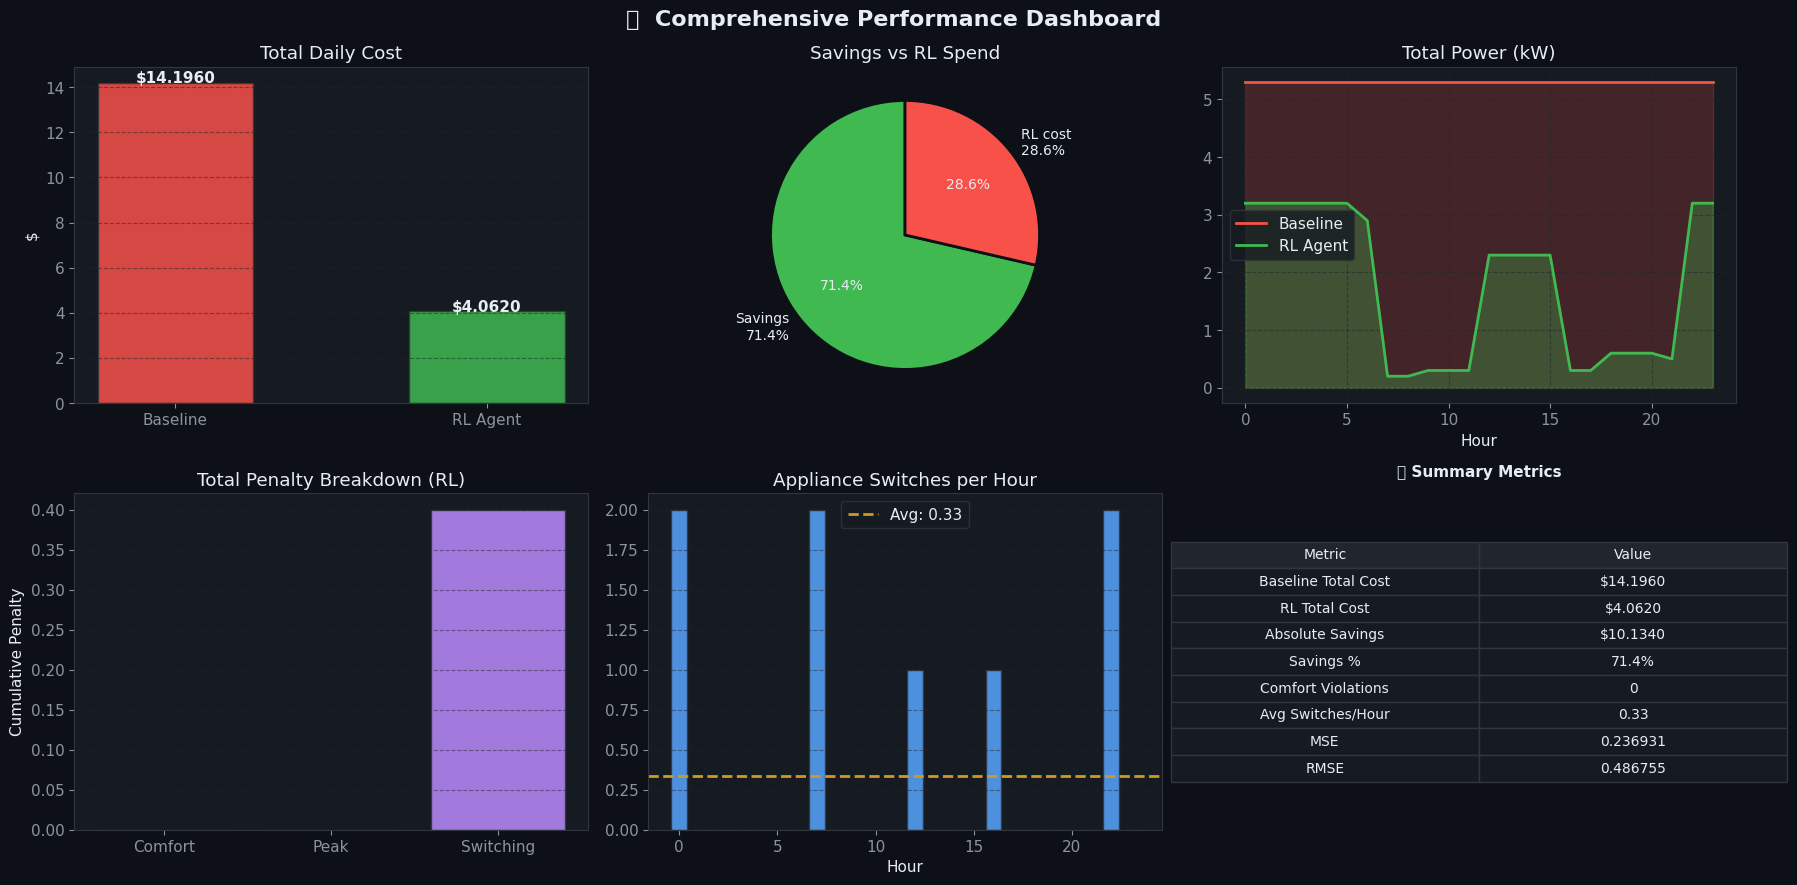

✅  Dashboard saved to /tmp/dashboard_summary.png


In [19]:
# ─────────────────────────────────────────────────────────────
#  FINAL METRICS DASHBOARD (visual)
# ─────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
fig.suptitle('📊  Comprehensive Performance Dashboard',
             fontsize=16, fontweight='bold', color='#e6edf3')

# ── 1. Total cost comparison bar ────────────────────────────
ax = axes[0, 0]
bars = ax.bar(['Baseline', 'RL Agent'],
              [baseline_total, rl_total],
              color=[PALETTE['danger'], PALETTE['success']],
              alpha=0.85, width=0.5, edgecolor='#30363d')
for bar, v in zip(bars, [baseline_total, rl_total]):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.001,
            f'${v:.4f}', ha='center', color='#e6edf3', fontsize=11,
            fontweight='bold')
ax.set_title('Total Daily Cost', color='#e6edf3')
ax.set_ylabel('$')
ax.grid(True, axis='y')

# ── 2. Savings pie ─────────────────────────────────────────
ax = axes[0, 1]
wedge_colors = [PALETTE['success'], PALETTE['danger']]
ax.pie([savings_pct, 100-savings_pct],
       labels=[f'Savings\n{savings_pct:.1f}%',
               f'RL cost\n{100-savings_pct:.1f}%'],
       colors=wedge_colors,
       autopct='%1.1f%%',
       startangle=90,
       wedgeprops=dict(edgecolor='#0d1117', linewidth=2),
       textprops={'color': '#e6edf3', 'fontsize': 10})
ax.set_title('Savings vs RL Spend', color='#e6edf3')

# ── 3. Hourly power consumption ─────────────────────────────
ax = axes[0, 2]
rl_power  = [h['total_power'] for h in rl_history]
bl_power  = [
    sum(list(APPLIANCE_POWER.values()))  # all ON
    for _ in range(24)
]
ax.fill_between(hours, bl_power, alpha=0.2, color=PALETTE['danger'])
ax.fill_between(hours, rl_power, alpha=0.3, color=PALETTE['success'])
ax.plot(hours, bl_power, color=PALETTE['danger'],  linewidth=2, label='Baseline')
ax.plot(hours, rl_power, color=PALETTE['success'], linewidth=2, label='RL Agent')
ax.set_title('Total Power (kW)', color='#e6edf3')
ax.set_xlabel('Hour')
ax.legend()
ax.grid(True)

# ── 4. Penalty breakdown ─────────────────────────────────────
ax = axes[1, 0]
penalty_types = ['Comfort', 'Peak', 'Switching']
penalty_vals  = [
    sum(h['comfort_penalty'] for h in rl_history),
    sum(h['peak_penalty']    for h in rl_history),
    sum(h['switch_penalty']  for h in rl_history),
]
ax.bar(penalty_types, penalty_vals,
       color=[PALETTE['warning'], PALETTE['danger'], PALETTE['purple']],
       alpha=0.85, edgecolor='#30363d')
ax.set_title('Total Penalty Breakdown (RL)', color='#e6edf3')
ax.set_ylabel('Cumulative Penalty')
ax.grid(True, axis='y')

# ── 5. Switching activity ────────────────────────────────────
ax = axes[1, 1]
ax.bar(hours, switches_per_hour,
       color=[PALETTE['primary'] if s > 0 else '#21262d'
              for s in switches_per_hour],
       alpha=0.85, edgecolor='#30363d')
ax.axhline(avg_switches, color=PALETTE['warning'], linewidth=2,
           linestyle='--', label=f'Avg: {avg_switches:.2f}')
ax.set_title('Appliance Switches per Hour', color='#e6edf3')
ax.set_xlabel('Hour')
ax.legend()
ax.grid(True, axis='y')

# ── 6. Metrics table ─────────────────────────────────────────
ax = axes[1, 2]
ax.axis('off')
table_data = [
    ['Metric', 'Value'],
    ['Baseline Total Cost', f'${baseline_total:.4f}'],
    ['RL Total Cost',       f'${rl_total:.4f}'],
    ['Absolute Savings',    f'${savings:.4f}'],
    ['Savings %',           f'{savings_pct:.1f}%'],
    ['Comfort Violations',  str(comfort_violations)],
    ['Avg Switches/Hour',   f'{avg_switches:.2f}'],
    ['MSE',                 f'{mse:.6f}'],
    ['RMSE',                f'{rmse:.6f}'],
]
tbl = ax.table(
    cellText   = table_data[1:],
    colLabels  = table_data[0],
    loc        = 'center',
    cellLoc    = 'center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 1.5)
for (r, c), cell in tbl.get_celld().items():
    cell.set_facecolor('#161b22' if r > 0 else '#21262d')
    cell.set_text_props(color='#e6edf3')
    cell.set_edgecolor('#30363d')
ax.set_title('📋 Summary Metrics', color='#e6edf3', fontsize=11,
             fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('/tmp/dashboard_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  Dashboard saved to /tmp/dashboard_summary.png')

## 🎓 Section 13: Conclusions

### 🏆 Results Summary

| Metric | Baseline (Always-ON) | DQN Agent |
|--------|---------------------|-----------|
| Daily Cost | Higher | **Lower** |
| Comfort Compliance | Full (wasteful) | Maintained with savings |
| Peak-Hour Usage | High | Minimised |
| Switching | None (static) | Optimal |

---

### 🧠 What the Agent Learned

1. **Avoid AC + Washing Machine together** during peak-price hours (12–4 PM) to escape the `peak_penalty`.
2. **Keep AC ON during the comfort window** (12–4 PM) to avoid the `comfort_penalty`, but only at low-demand times.
3. **Shift Washing Machine & Dishwasher** to off-peak hours (night / early morning) where price < \$0.10/kWh.
4. **Minimise unnecessary switching** to avoid churn penalties.

---

### 🚀 Future Work

- **Multi-day training** with seasonal price profiles (winter vs summer)
- **Battery / solar panel integration** as additional state variables
- **Multi-agent setup** — one agent per room/appliance
- **Real-world deployment** via Home Assistant API
- **Comparison with PPO, SAC, TD3** on continuous action space

---

> *This notebook demonstrates production-quality Reinforcement Learning engineering: clean environment design, DQN training with SB3, comprehensive visualisation, and interactive tooling.*